# Step 7: Bayesian search for the ranker

The earlier ranker used small five-trial inner searches. This notebook runs **50 completed Optuna TPE trials** over eight hyperparameters. Each trial returns mean Top-1 across the same five saved trip folds.

Default search fidelity: one fixed sample of **10,000 whole GPS groups**, covering every training trip. Every candidate for a sampled point stays together. Set `search_groups = None` for full-row search. The next notebook evaluates both configurations on **all training rows** and then on the untouched student-test trips.

Sampling limits search cost; it does not turn the selected CV score into an unbiased estimate. Parameters were selected using these folds. Use the independent student-test comparison as the holdout check. Do not re-tune after viewing its scores.

In [1]:
%run 06_model_helpers.ipynb
import optuna
import xgboost as xgb
import matplotlib.pyplot as plt
from datetime import datetime
from zoneinfo import ZoneInfo

search_groups = 10000
n_trials = 50
n_jobs = 4
mode = "full" if search_groups is None else f"sample{search_groups}"
output = Path("outputs") / f"step7_xgb_{mode}"
output.mkdir(parents=True, exist_ok=True)
config = {"search_groups": search_groups, "trials": n_trials, "seed": seed, "n_jobs": n_jobs,
          "fold_file": contract["fold_file"], "features": feature_columns,
          "search_space": {"max_depth": [3, 6], "learning_rate": [0.03, 0.3],
              "n_estimators": [50, 100, 150], "min_child_weight": [1, 20],
              "subsample": [0.6, 1], "colsample_bytree": [0.6, 1],
              "reg_lambda": [0.1, 100], "gamma": [1e-8, 5]}}
if (output / "config.json").exists():
    assert json.loads((output / "config.json").read_text()) == config
(output / "config.json").write_text(json.dumps(config, indent=2) + "\n")
data, points = load_model_data()
if search_groups is not None:
    required = points.groupby("trip_id", group_keys=False).sample(n=1, random_state=seed)
    remaining = points[~points["group_id"].isin(required["group_id"])]
    extra = remaining.sample(n=min(search_groups - len(required), len(remaining)), random_state=seed)
    selected = pd.concat([required, extra]).sort_values("group_id")
    search_data = data[data["group_id"].isin(selected["group_id"])].copy()
    search_points = selected.copy()
else:
    search_data, search_points = data, points
search_points[["trip_id", "group_id", "fold"]].to_csv(output / "search_groups.csv", index=False)
assert search_points["trip_id"].nunique() == points["trip_id"].nunique()
assert search_points.groupby("trip_id")["fold"].nunique().eq(1).all()
print("Search rows:", len(search_data), "| GPS groups:", len(search_points), "| Trips:", search_points["trip_id"].nunique(), flush=True)

/Users/admin/.pyenv/versions/3.11.9/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Search rows: 554016 | GPS groups: 10000 | Trips: 80


## Objective

Keep the ranker's query order and group sizes after splitting. Exclude singleton and no-positive groups from fitting only. Score all valid held-out groups, including candidate misses.

Learning rate, L2 penalty and gamma use log scales. Gamma's positive lower bound approximates an unpenalized split. Cap tree count at 150. The first ten TPE trials explore randomly; subsequent trials adapt to completed results. No pruning is used, so each completed trial evaluates all five folds.

In [2]:
def fit_ranker(frame, params):
    sizes = frame.groupby("group_id")["label"].agg(["size", "sum"])
    eligible = sizes.index[(sizes["size"] >= 2) & (sizes["sum"] == 1)]
    training = frame[frame["group_id"].isin(eligible)]
    assert training["group_id"].is_monotonic_increasing
    groups = training.groupby("group_id", sort=False).size().to_numpy()
    model = xgb.XGBRanker(objective="rank:ndcg", eval_metric="ndcg@1", tree_method="hist",
                          random_state=seed, n_jobs=n_jobs, **params)
    model.fit(training[feature_columns], training["label"], group=groups, verbose=False)
    return model


In [3]:
def objective(trial):
    params = {"max_depth": trial.suggest_int("max_depth", 3, 6),
              "learning_rate": trial.suggest_float("learning_rate", 0.03, 0.3, log=True),
              "n_estimators": trial.suggest_categorical("n_estimators", [50, 100, 150]),
              "min_child_weight": trial.suggest_float("min_child_weight", 1, 20),
              "subsample": trial.suggest_float("subsample", 0.6, 1),
              "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1),
              "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 100, log=True),
              "gamma": trial.suggest_float("gamma", 1e-8, 5, log=True)}
    scores = []
    for fold in range(5):
        training = search_data[search_data["fold"] != fold]
        validation = search_data[search_data["fold"] == fold]
        valid_points = search_points[search_points["fold"] == fold]
        assert set(training["trip_id"]).isdisjoint(validation["trip_id"])
        model = fit_ranker(training, params)
        probability = point_softmax(model.predict(validation[feature_columns]), validation["group_id"])
        scores.append(score_points(validation, probability, valid_points)["top1"])
    trial.set_user_attr("fold_top1", scores)
    return float(np.mean(scores))


def save_history(study, trial):
    study.trials_dataframe().to_csv(output / "trials.csv", index=False)
    if trial.value is None:
        print("Trial", trial.number + 1, trial.state.name, flush=True)
        return
    print("Trial", trial.number + 1, "| Mean Top-1:", round(trial.value, 5),
          "| Best:", round(study.best_value, 5), flush=True)

## Run and retain history

SQLite retains completed trials if interrupted. The CSV is updated after every trial. Re-running uses the same frozen search sample and resumes until 50 trials are complete. Trial history, rather than a claim of identical sampler state after an interruption, is the reproducibility record.

In [4]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="maximize", study_name="step7_ranker",
    sampler=optuna.samplers.TPESampler(seed=seed, n_startup_trials=10),
    pruner=optuna.pruners.NopPruner(), storage=f"sqlite:///{output / 'study.sqlite3'}", load_if_exists=True)
completed = len(study.get_trials(states=[optuna.trial.TrialState.COMPLETE]))
study.optimize(objective, n_trials=max(0, n_trials - completed), callbacks=[save_history])
assert len(study.get_trials(states=[optuna.trial.TrialState.COMPLETE])) >= n_trials
history = study.trials_dataframe()
history.to_csv(output / "trials.csv", index=False)
frozen = {"params": study.best_params, "search_cv_top1": study.best_value,
          "search_groups": len(search_points), "search_rows": len(search_data),
          "search_mode": mode, "seed": seed,
          "selected_at": datetime.now(ZoneInfo("Asia/Kolkata")).isoformat(),
          "fold_file": contract["fold_file"], "completed_trials": n_trials}
if (output / "best_params.json").exists():
    previous = json.loads((output / "best_params.json").read_text())
    assert previous["params"] == frozen["params"]
    frozen = previous
else:
    (output / "best_params.json").write_text(json.dumps(frozen, indent=2) + "\n")
print("Frozen best configuration:", frozen)

Trial 29 | Mean Top-1: 0.79232 | Best: 0.79232


Trial 30 | Mean Top-1: 0.79115 | Best: 0.79232


Trial 31 | Mean Top-1: 0.79362 | Best: 0.79362


Trial 32 | Mean Top-1: 0.7905 | Best: 0.79362


Trial 33 | Mean Top-1: 0.78966 | Best: 0.79362


Trial 34 | Mean Top-1: 0.79046 | Best: 0.79362


... (14 outputs left out)

Trial 49 | Mean Top-1: 0.79134 | Best: 0.79362


Trial 50 | Mean Top-1: 0.79064 | Best: 0.79362


Trial 51 | Mean Top-1: 0.79216 | Best: 0.79362


Frozen best configuration: {'params': {'max_depth': 6, 'learning_rate': 0.29992371455654276, 'n_estimators': 50, 'min_child_weight': 2.968888733614375, 'subsample': 0.7653830020461954, 'colsample_bytree': 0.6828369642189636, 'reg_lambda': 0.1627321975366077, 'gamma': 1.0947188593873698}, 'search_cv_top1': 0.7936171348233958, 'search_groups': 10000, 'search_rows': 554016, 'search_mode': 'sample10000', 'seed': 42, 'selected_at': '2026-11-18T13:54:09.836407+05:30', 'fold_file': 'outputs/folds/group_folds.csv', 'completed_trials': 50}


## Search evidence

Best-score-so-far shows whether progress was still occurring at the end of this bounded search. Parameter importances summarize this study only; 50 trials cannot establish that an unimportant-looking parameter never matters.

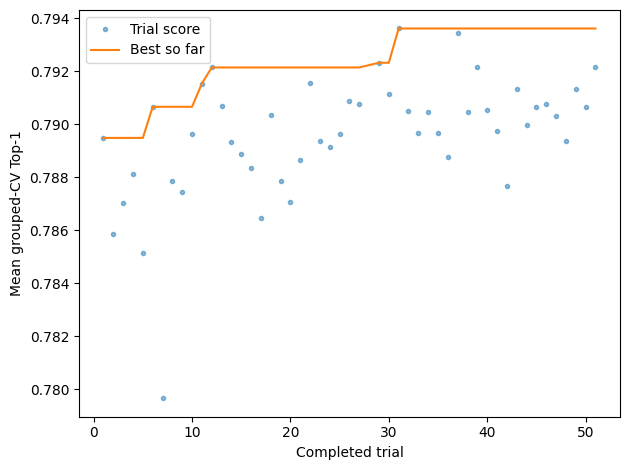

,importance
learning_rate,0.336289
colsample_bytree,0.308494
max_depth,0.123635
gamma,0.096282
subsample,0.067406
min_child_weight,0.035737
reg_lambda,0.027506
n_estimators,0.004651


In [5]:
complete = history[history["state"] == "COMPLETE"]
plt.plot(complete["number"] + 1, complete["value"], ".", alpha=0.5, label="Trial score")
plt.plot(complete["number"] + 1, complete["value"].cummax(), label="Best so far")
plt.xlabel("Optuna trial number")
plt.ylabel("Mean grouped-CV Top-1")
plt.legend()
plt.tight_layout()
plt.savefig(output / "convergence.png", dpi=150)
plt.show()
importance = optuna.importance.get_param_importances(study,
    evaluator=optuna.importance.FanovaImportanceEvaluator(seed=seed))
(output / "parameter_importance.json").write_text(json.dumps(importance, indent=2) + "\n")
display(pd.Series(importance, name="importance").to_frame())